# Telecom Customer Churn Analysis
## 03 — Exploratory Data Analysis

### Objective

Explore customer characteristics and identify patterns associated with customer churn.

### Business Questions

- Why are customers leaving?
- Which customer groups show higher churn? and
- What factors may be associated with customer retention?

In [1]:
import pandas as pd

In [2]:
dataset = r"C:\Users\HomePC\Desktop\Data Analysis Portfolio\telecom_customer_churn_analysis\data\telecom_customer_churn_clean.csv"
df_clean = pd.read_csv(dataset)

In [3]:
df_clean.shape

(7043, 38)

In [4]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   object 
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   object 
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   objec

In [22]:
# Show the counts of each status group

df_clean["Customer Status"].value_counts()

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

In [6]:
# Find the percentage proportion of each status group

df_clean["Customer Status"].value_counts(normalize=True).mul(100).round(2)

Customer Status
Stayed     67.02
Churned    26.54
Joined      6.45
Name: proportion, dtype: float64

In [26]:
# Summarize in a table 

status_summary = (
    df_clean["Customer Status"]
    .value_counts()
    .rename_axis("Customer Status")
    .reset_index(name="Number of Customers")
)

status_summary["Percentage"] = (
    status_summary["Number of Customers"]
    / status_summary["Number of Customers"].sum()
    * 100
).round(2)

status_summary

,Customer Status,Number of Customers,Percentage
0,Stayed,4720,67.02
1,Churned,1869,26.54
2,Joined,454,6.45


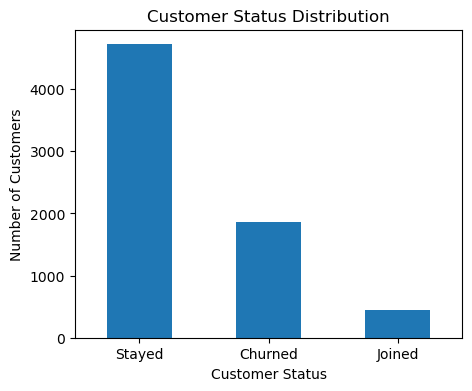

In [29]:
# Visualize

import matplotlib.pyplot as plt

status_counts = df_clean["Customer Status"].value_counts()

plt.figure(figsize=(5,4))
status_counts.plot(kind="bar")

plt.title("Customer Status Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

### Notes

**Customer Status Distribution**

The dataset contains 7,043 customer records. Of these, 
4,720 customers (67.02%) are classified as Stayed, 
1,869 (26.54%) as Churned, and 
454 (6.45%) as Joined.

A key observation is that Churned customers account for 26.54% of all records, making churn an important area for further investigation.

So, next step is to investigate how churn varies across customer characteristics, contracts, and subscribed services to identify patterns that may help inform retention strategies.

### Investigate Customer churn

In [30]:
# Customer Tenure -- find out whether churn is more common among newer customers or customers who have been with the company longer.


df_clean.groupby("Customer Status")["Tenure in Months"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Customer Status,,,,,,,,
Churned,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0
Joined,454.0,1.72,0.82,1.0,1.0,1.0,2.0,3.0
Stayed,4720.0,41.04,22.36,4.0,21.0,42.0,63.0,72.0


### Customer Tenure by Status

1. Churned customers generally had shorter tenures than customers who stayed.
The average tenure for churned customers was approximately 18 months, compared with 41 months for customers who stayed.

2. The median tenure for churned customers was only 10 months.
This means half of the customers classified as churned had a tenure of 10 months or less. That suggests the early customer relationship may deserve closer investigation.

3. Customers who stayed had substantially longer tenures.
Their median tenure was 42 months. Longer-tenure customers may have developed stronger relationships with the company, although this analysis alone cannot establish why they stayed.

4. Joined customers are a separate group.
Their average tenure was only 1.72 months, which is consistent with them being relatively new customers. We should not combine them with churned customers when investigating churn patterns.


**Key observation:** Churned customers generally had shorter tenures than customers who stayed. This suggests that customer tenure is an important variable to investigate further when exploring churn patterns.

**Business implication:** The company could investigate the early stages of the customer relationship to identify potential opportunities to improve retention.

<Figure size 900x500 with 0 Axes>

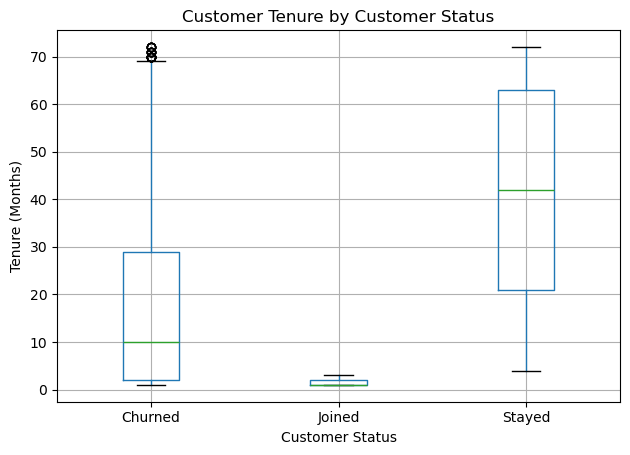

In [31]:
# Visualize

plt.figure(figsize=(9, 5))

df_clean.boxplot(
    column="Tenure in Months",
    by="Customer Status"
)

plt.title("Customer Tenure by Customer Status")
plt.suptitle("")
plt.xlabel("Customer Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

### Customer status by Contract type

In [32]:
#  Investigate whether the proportion of customers who churned differs by contract type.

df_clean["Contract"].value_counts()

Contract
Month-to-Month    3610
Two Year          1883
One Year          1550
Name: count, dtype: int64

In [33]:
# Create a table showing customer status within each contract type

pd.crosstab(
    df_clean["Contract"],
    df_clean["Customer Status"]
)

Customer Status,Churned,Joined,Stayed
Contract,,,
Month-to-Month,1655,408,1547
One Year,166,24,1360
Two Year,48,22,1813


In [34]:
# Calculate the percentage distribution of customer status within each contract type

pd.crosstab(
    df_clean["Contract"],
    df_clean["Customer Status"],
    normalize="index"
).mul(100).round(2)

Customer Status,Churned,Joined,Stayed
Contract,,,
Month-to-Month,45.84,11.30,42.85
One Year,10.71,1.55,87.74
Two Year,2.55,1.17,96.28


### Customer Status by Contract Type

The percentages were calculated within each contract type.
Customer status differs substantially across contract types.

Among month-to-month customers, 45.84% are classified as Churned, compared with 10.71% of one-year contract customers and 2.55% of two-year contract customers.

The proportion classified as Stayed increases with contract duration, from 42.85% for month-to-month customers to 87.74% for one-year customers and 96.28% for two-year customers.

**Key observation:** Month-to-month customers have the highest observed churn share, while two-year customers have the lowest.

**Business implication:** The company could investigate the experiences, pricing, and service issues of month-to-month customers and evaluate retention strategies tailored to this group.

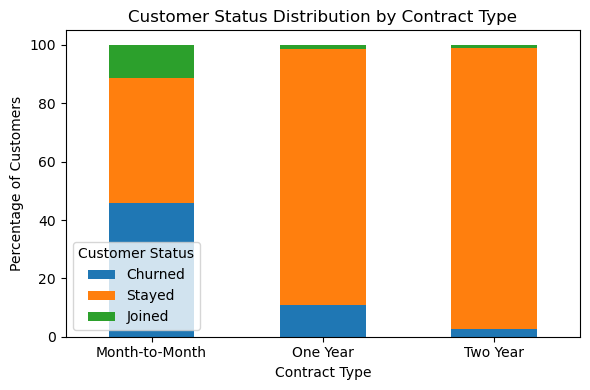

In [37]:
# Visualize

contract_status_pct = (
    pd.crosstab(
        df_clean["Contract"],
        df_clean["Customer Status"],
        normalize="index"
    ) * 100
)

contract_status_pct = contract_status_pct[
    ["Churned", "Stayed", "Joined"]
]

contract_status_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(6, 4)
)

plt.title("Customer Status Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

### Customer churn by Internet service 

In [38]:
# Create a table showing customer status within each internet service group

pd.crosstab(
    df_clean["Internet Service"],
    df_clean["Customer Status"]
)

Customer Status,Churned,Joined,Stayed
Internet Service,,,
No,113,182,1231
Yes,1756,272,3489


In [39]:
# Calculate percentages

pd.crosstab(
    df_clean["Internet Service"],
    df_clean["Customer Status"],
    normalize="index"
).mul(100).round(2)

Customer Status,Churned,Joined,Stayed
Internet Service,,,
No,7.40,11.93,80.67
Yes,31.83,4.93,63.24


### Notes

The results show a notable difference between customers with and without internet service.

Among customers with internet service, 31.83% Churned, compared with 7.40% of customers without internet service. 
For Stayed customers, 63.24% had internet service and 80.67% were without internet service.

**Key observation:** Customers with internet service have a substantially higher observed churn share.

**Business implication:** Further analysis should examine whether churn patterns differ by internet type and by the specific services customers subscribe to.

### Customer churn by Internet type

In [17]:
internet_customers = df_clean[
    df_clean["Internet Service"] == "Yes"
]

pd.crosstab(
    internet_customers["Internet Type"],
    internet_customers["Customer Status"],
    normalize="index"
).mul(100).round(2)

Customer Status,Churned,Joined,Stayed
Internet Type,,,
Cable,25.66,6.75,67.59
DSL,18.58,6.96,74.46
Fiber Optic,40.72,3.33,55.95


### Notes

Customer status distributions vary across internet types.

Fiber Optic customers have the highest observed churn share at 40.72%, followed by Cable customers at 25.66% and DSL customers at 18.58%.

DSL customers also have the highest proportion classified as Stayed, at 74.46%.

**Key observation:** Fiber Optic customers show a substantially higher observed churn share than customers using DSL or Cable.

**Business implication:** The company should investigate the pricing, contract arrangements, service quality, and support experiences of Fiber Optic customers to identify potential retention opportunities.

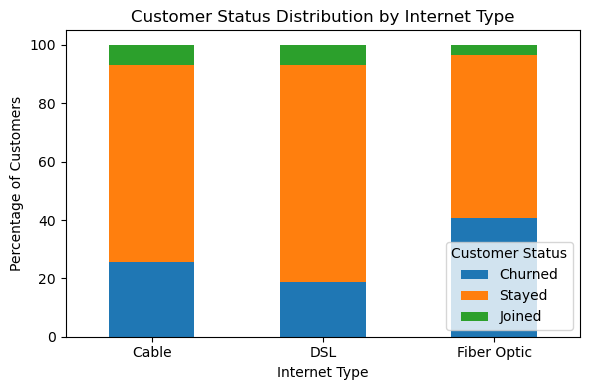

In [43]:
# Visualize

internet_type_pct =pd.crosstab(
    internet_customers["Internet Type"],
    internet_customers["Customer Status"],
    normalize="index"
).mul(100)

internet_type_pct = internet_type_pct[
    ["Churned", "Stayed", "Joined"]
]

internet_type_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(6, 4)
)

plt.title("Customer Status Distribution by Internet Type")
plt.xlabel("Internet Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

### Demographics analysis

In [48]:
# find the average 'age' and average 'number of dependents' across Customer status


print("Average age and Average number of dependents across Customer status")
print("")

df_clean.groupby("Customer Status")[
    ["Age", "Number of Dependents"]
].mean().round(2)

Average age and Average number of dependents across Customer status



,Age,Number of Dependents
Customer Status,,
Churned,49.74,0.12
Joined,42.87,0.36
Stayed,45.58,0.62


### Notes

**Findings:** 

**Age:** Churned customers had the highest average age (49.74 years), compared with 45.58 years for customers who stayed and 42.87 years for newly joined customers.
That is, older customers are more likely to churn than younger ones

**Number of Dependents:** Customers who stayed had an average of 0.62 dependents, compared with 0.12 among churned customers. 
This implies that the higher the number of dependents, the more likely the customer will stay.

In [50]:
# Calculate the percentage distribution of customer status by Gender and Marital status

for column in ["Gender", "Married"]:
    print(f"\n{column} by Customer Status")

    display(
        pd.crosstab(
            df_clean[column],
            df_clean["Customer Status"],
            normalize="index"
        ).mul(100).round(2)
    )


Gender by Customer Status


Customer Status,Churned,Joined,Stayed
Gender,,,
Female,26.92,6.05,67.03
Male,26.16,6.84,67.00



Married by Customer Status


Customer Status,Churned,Joined,Stayed
Married,,,
No,32.96,10.16,56.88
Yes,19.66,2.47,77.87


### Notes

**Key Findings**

**Gender:** Churn shares were similar for female customers (26.92%) and male customers (26.16%). Gender did not show a substantial difference in observed churn share.

**Marital Status:** Customers who were not married had a higher observed churn share (32.96%) than married customers (19.66%). Married customers also had a higher share of customers who stayed.

Therefore, Marital status shows a more noticeable association with customer status than gender does.

In [51]:
# Investigate whether individual services are associated with customer churn (Online Security, Premium Tech Support,Device Protection Plan).

service_cols = [
    "Online Security",
    "Premium Tech Support",
    "Device Protection Plan"
]

for column in service_cols:
    print(f"\n{column} by Customer Status")

    display(
        pd.crosstab(
            df_clean[column],
            df_clean["Customer Status"],
            normalize="index"
        ).mul(100).round(2)
    )


Online Security by Customer Status


Customer Status,Churned,Joined,Stayed
Online Security,,,
No,31.33,8.12,60.55
Yes,14.61,2.28,83.11



Premium Tech Support by Customer Status


Customer Status,Churned,Joined,Stayed
Premium Tech Support,,,
No,31.19,8.14,60.67
Yes,15.17,2.30,82.53



Device Protection Plan by Customer Status


Customer Status,Churned,Joined,Stayed
Device Protection Plan,,,
No,28.65,9.13,62.22
Yes,22.50,1.32,76.18


### Key Findings — Individual Service Analysis

**Online Security:** Customers without Online Security had a higher observed churn share (31.33%) than customers with the service (14.61%), a difference of 16.72 percentage points.

**Premium Tech Support:** Customers without Premium Tech Support had a higher observed churn share (31.19%) than customers with the service (15.17%), a difference of 16.02 percentage points.

**Device Protection Plan:** Customers without Device Protection Plan had a higher observed churn share (28.65%) than customers with the service (22.50%), a difference of 6.15 percentage points.

**Business Implication:** Online Security and Premium Tech Support show the largest differences in observed churn share among these three services. The company could investigate customer needs, service awareness, support experience, and suitable bundles.

### Monthly charges analysis

In [21]:
df_clean.groupby("Customer Status")["Monthly Charge"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
Customer Status,,,,
Churned,1839,74.62,79.65,24.60
Joined,448,43.41,44.00,24.16
Stayed,4636,62.96,66.40,31.17


### Key Findings — Monthly Charge Analysis 

Churned customers had a mean monthly charge of 74.62 and a median of 79.65. Customers who stayed had a mean of 62.96 and a median of 66.40, while newly joined customers had a mean of 43.41 and a median of 44.00.

Both the mean and median monthly charges were higher among churned customers than among customers who stayed. This suggests a possible association between monthly charges and churn.

**Business Implication:** The company should investigate whether customers with higher monthly charges receive sufficient value from their plans. 

# Exploratory Data Analysis Summary

## 1. Overview

The purpose of this exploratory data analysis (EDA) was to investigate customer characteristics and identify patterns associated with customer churn in the telecom dataset.

The dataset contains 7,043 customer records and 38 columns. The analysis examined customer status, tenure, contract type, internet service, demographics, selected additional services, and monthly charges.

The objective was to identify meaningful patterns that could help the business better understand customer retention and identify areas for further investigation.

## 2. Key Findings

### Customer Status

Of the 7,043 customer records:
- **Stayed:** 4,720 customers (67.02%)
- **Churned:** 1,869 customers (26.54%)
- **Joined:** 454 customers (6.45%)

Churned customers represented 26.54% of all records. 

### Customer Tenure

Customers who churned had a median tenure of 10 months, compared with 42 months for customers who stayed. Churned customers also had a lower mean tenure of 17.98 months, compared with 41.04 months among customers who stayed.

This indicates that churned customers generally had shorter relationships with the company. Customer retention efforts may therefore benefit from investigating the early stages of the customer journey.

Newly joined customers had a median tenure of one month, which is consistent with their recent arrival.

### Contract Type

Contract type showed a substantial association with customer status.

- **Month-to-month:** 45.84% churned.
- **One-year:** 10.71% churned.
- **Two-year:** 2.55% churned.

Customers on month-to-month contracts had a much higher observed churn share than customers on longer-term contracts. Customers on two-year contracts had the lowest observed churn share.

The business could investigate whether contract duration, customer commitment, pricing, or other differences help explain this pattern. 

### Internet Service and Internet Type

Customers with internet service had an observed churn share of 31.83%, compared with 7.40% among customers without internet service.

Among customers who had internet service, churn shares differed by internet type:

- **Fiber Optic:** 40.72%
- **Cable:** 25.66%
- **DSL:** 18.58%

Fiber Optic customers had the highest observed churn share among the three internet types. This group may warrant further investigation into pricing, service quality, technical support, and customer expectations.

These comparisons show associations and do not identify the underlying causes of churn.

### Demographic Characteristics

Churned customers had a higher average age (49.74 years) than customers who stayed (45.58 years). They also had fewer dependents on average: 0.12 compared with 0.62 among customers who stayed.

Gender showed little difference in observed churn share. The share was 26.92% among female customers and 26.16% among male customers.

Marital status showed a more noticeable difference. Customers who were not married had an observed churn share of 32.96%, compared with 19.66% among married customers.

These demographic patterns may support further customer segmentation, but should be interpreted alongside other factors such as tenure and contract type.

### Additional Services

Customers without Online Security had an observed churn share of 31.33%, compared with 14.61% among customers with the service.

Similarly, customers without Premium Tech Support had an observed churn share of 31.19%, compared with 15.17% among customers with the service.

For Device Protection Plan, the churn share was 28.65% among customers without the service and 22.50% among customers with it.

The differences were largest for Online Security and Premium Tech Support. The company could investigate customer awareness, support experiences, and whether suitable service bundles would address customer needs.

### Monthly Charges

Churned customers had a mean monthly charge of 74.62 and a median of 79.65. Customers who stayed had a mean of 62.96 and a median of 66.40.

Newly joined customers had the lowest typical monthly charges, with a mean of 43.41 and a median of 44.00.

The higher mean and median among churned customers suggest that monthly charges may be associated with churn. Further investigation should examine whether this pattern reflects differences in contract type, service subscriptions, tenure, or perceived value.

The statistics exclude records with missing monthly charges, including the 120 suspicious negative values marked as missing during data cleaning.

## 3. Business Recommendations

Based on the observed patterns, the following areas deserve further investigation:

1. **Review early customer retention.** Investigate why customers with shorter tenure are more represented among churned customers and identify opportunities to improve the early customer experience.

2. **Investigate month-to-month contracts.** Explore whether pricing, contract flexibility, or differences in customer characteristics help explain their higher churn share.

3. **Examine Fiber Optic customer experiences.** Investigate pricing, reliability, service quality, and support experiences among Fiber Optic customers.

4. **Review additional service adoption.** Explore whether customers without Online Security and Premium Tech Support have unmet needs or would benefit from better service information and suitable bundles.

5. **Investigate higher monthly charges.** Compare charges with contract type and subscribed services to understand whether customers paying more are receiving value that meets their expectations.

6. **Use demographic patterns cautiously.** Consider age, dependents, and marital status as potential segmentation variables for further analysis, while avoiding assumptions about individual customers.


## 4. Limitations of the Analysis

- The analysis is descriptive and identifies associations rather than causal relationships.
- Some monthly charge values were flagged as suspicious and treated as missing because their cause could not be established.
- Missing Offer values were retained because the available evidence did not justify interpreting them as customers who received no offer.
- Differences between customer groups may reflect other variables that have not yet been examined together.

## 5. Conclusion

The exploratory analysis identified several patterns associated with customer churn. The most notable include the higher churn share among month-to-month contract customers, the shorter tenure of churned customers, the higher churn share among Fiber Optic customers, and the differences associated with Online Security, Premium Tech Support, and monthly charges.

These findings provide a foundation for deeper analysis using SQL and visualizations. Further investigation should examine how these factors interact before the business makes decisions about pricing, service offerings, or customer retention strategies.

The next stage of the project will build on these findings to develop more focused business insights and practical recommendations.